## NB09 — Comparação dos Modelos e Construção do Ranking de Risco

**Entrada:** `data/load/dataset_ml_model.csv` — 76.218 linhas × 26 colunas  
**Saída:** `data/output/ranking_parcial.csv` — tabela ordenada de risco com scores dos 3 modelos

**Objetivo:**
- Comparar os modelos: sobreposição de anomalias, correlação de scores
- Construir o ranking combinado de risco
- Analisar o perfil das propostas mais anômalas

---
### 0. Imports e Configuração

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

RANDOM_STATE = 42
CONTAMINATION = 0.01

os.makedirs('data/output', exist_ok=True)
print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

---
### 1. Carregamento e Separação de Identificadores

In [3]:
df_full = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape completo: {df_full.shape}')
print(f'\nColunas: {df_full.columns.tolist()}')

Shape completo: (76218, 26)

Colunas: ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']


In [4]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_ids  = df_full[identificadores].copy()
df_feat = df_full.drop(columns=identificadores).copy()

feature_cols = df_feat.columns.tolist()

print(f'Features para modelagem ({len(feature_cols)}): {feature_cols}')
print(f'\nShape features: {df_feat.shape}')
print(f'NaN nas features: {df_feat.isnull().sum().sum()}')

Features para modelagem (21): ['desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']

Shape features: (76218, 21)
NaN nas features: 0


---
### 2. Treinamento dos Modelos

Reprodução fiel dos hiperparâmetros definidos no NB08.

#### 2.1 Isolation Forest

In [5]:
print('Treinando Isolation Forest...')

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=CONTAMINATION,
    max_samples=256,
    random_state=RANDOM_STATE
)
iso_forest.fit(df_feat)

df_feat['if_score']  = iso_forest.decision_function(df_feat[feature_cols])
df_feat['if_label']  = iso_forest.predict(df_feat[feature_cols])  # 1=normal, -1=anomalia

n_if = (df_feat['if_label'] == -1).sum()
print(f'IF → {n_if} anomalias ({n_if/len(df_feat):.1%})')

Treinando Isolation Forest...


IF → 741 anomalias (1.0%)


#### 2.2 Local Outlier Factor

In [6]:
print('Treinando Local Outlier Factor...')

lof = LocalOutlierFactor(
    n_neighbors=50,        
    contamination=CONTAMINATION
)
lof_preds  = lof.fit_predict(df_feat[feature_cols])
lof_scores = -lof.negative_outlier_factor_ 

df_feat['lof_score'] = lof_scores
df_feat['lof_label'] = lof_preds  # 1=normal, -1=anomalia

n_lof = (df_feat['lof_label'] == -1).sum()
print(f'LOF → {n_lof} anomalias ({n_lof/len(df_feat):.1%})')

Treinando Local Outlier Factor...


LOF → 763 anomalias (1.0%)


#### 2.3 One-Class SVM (com StandardScaler)

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_feat[feature_cols])

print('Treinando One-Class SVM...')
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_scaled)

df_feat['ocsvm_score'] = ocsvm.decision_function(X_scaled)
df_feat['ocsvm_label'] = ocsvm.predict(X_scaled)  # 1=normal, -1=anomalia

n_ocsvm = (df_feat['ocsvm_label'] == -1).sum()
print(f'OCSVM → {n_ocsvm} anomalias ({n_ocsvm/len(df_feat):.1%})')

Treinando One-Class SVM...


OCSVM → 993 anomalias (1.3%)


---
### 3. Tabela Comparativa Inicial

In [8]:
comparativo = pd.DataFrame({
    'Modelo': ['Isolation Forest', 'Local Outlier Factor', 'One-Class SVM'],
    'Hiperparâmetros': [
        'n_estimators=100, max_samples=256, contamination=0.01',
        'n_neighbors=50, contamination=0.01',
        'kernel=rbf, nu=0.01, gamma=scale + StandardScaler'
    ],
    'Anomalias Detectadas': [
        (df_feat['if_label'] == -1).sum(),
        (df_feat['lof_label'] == -1).sum(),
        (df_feat['ocsvm_label'] == -1).sum()
    ],
    '% da Base': [
        f"{(df_feat['if_label'] == -1).mean():.2%}",
        f"{(df_feat['lof_label'] == -1).mean():.2%}",
        f"{(df_feat['ocsvm_label'] == -1).mean():.2%}"
    ]
})

print('=== Tabela Comparativa dos Modelos ===')
print(comparativo.to_string(index=False))

=== Tabela Comparativa dos Modelos ===
              Modelo                                       Hiperparâmetros  Anomalias Detectadas % da Base
    Isolation Forest n_estimators=100, max_samples=256, contamination=0.01                   741     0.97%
Local Outlier Factor                    n_neighbors=50, contamination=0.01                   763     1.00%
       One-Class SVM     kernel=rbf, nu=0.01, gamma=scale + StandardScaler                   993     1.30%


---
### 4. Análise de Sobreposição (Overlap)

Quantas propostas são sinalizadas por 1, 2 ou 3 modelos simultaneamente?

In [9]:
set_if    = set(df_feat[df_feat['if_label']    == -1].index)
set_lof   = set(df_feat[df_feat['lof_label']   == -1].index)
set_ocsvm = set(df_feat[df_feat['ocsvm_label'] == -1].index)

todos_3    = set_if & set_lof & set_ocsvm
if_lof     = (set_if & set_lof)    - todos_3
if_ocsvm   = (set_if & set_ocsvm)  - todos_3
lof_ocsvm  = (set_lof & set_ocsvm) - todos_3
so_if      = set_if    - set_lof - set_ocsvm
so_lof     = set_lof   - set_if  - set_ocsvm
so_ocsvm   = set_ocsvm - set_if  - set_lof

print('=== Sobreposição entre Modelos ===')
print(f'Flagados pelos 3 modelos:       {len(todos_3):>5} ({len(todos_3)/len(df_feat):.3%})')
print(f'Apenas IF + LOF:                {len(if_lof):>5} ({len(if_lof)/len(df_feat):.3%})')
print(f'Apenas IF + OCSVM:              {len(if_ocsvm):>5} ({len(if_ocsvm)/len(df_feat):.3%})')
print(f'Apenas LOF + OCSVM:             {len(lof_ocsvm):>5} ({len(lof_ocsvm)/len(df_feat):.3%})')
print(f'Apenas IF:                      {len(so_if):>5} ({len(so_if)/len(df_feat):.3%})')
print(f'Apenas LOF:                     {len(so_lof):>5} ({len(so_lof)/len(df_feat):.3%})')
print(f'Apenas OCSVM:                   {len(so_ocsvm):>5} ({len(so_ocsvm)/len(df_feat):.3%})')
print(f'\nUnião total (≥1 modelo):        {len(set_if|set_lof|set_ocsvm):>5} ({len(set_if|set_lof|set_ocsvm)/len(df_feat):.3%})')

=== Sobreposição entre Modelos ===
Flagados pelos 3 modelos:           2 (0.003%)
Apenas IF + LOF:                   22 (0.029%)
Apenas IF + OCSVM:                281 (0.369%)
Apenas LOF + OCSVM:                 4 (0.005%)
Apenas IF:                        436 (0.572%)
Apenas LOF:                       735 (0.964%)
Apenas OCSVM:                     706 (0.926%)

União total (≥1 modelo):         2186 (2.868%)


In [10]:
df_feat['votos'] = (
    (df_feat['if_label']    == -1).astype(int) +
    (df_feat['lof_label']   == -1).astype(int) +
    (df_feat['ocsvm_label'] == -1).astype(int)
)

votos_dist = df_feat['votos'].value_counts().sort_index()
print('=== Distribuição de Votos ===')
for v, n in votos_dist.items():
    label = {
        0: 'Normal (nenhum modelo)',
        1: 'Baixo risco (1 modelo)',
        2: 'Médio risco (2 modelos)',
        3: 'Alto risco (3 modelos)'
    }[v]
    print(f'  {v} voto(s) — {label}: {n:>6} ({n/len(df_feat):.2%})')

=== Distribuição de Votos ===
  0 voto(s) — Normal (nenhum modelo):  74032 (97.13%)
  1 voto(s) — Baixo risco (1 modelo):   1877 (2.46%)
  2 voto(s) — Médio risco (2 modelos):    307 (0.40%)
  3 voto(s) — Alto risco (3 modelos):      2 (0.00%)


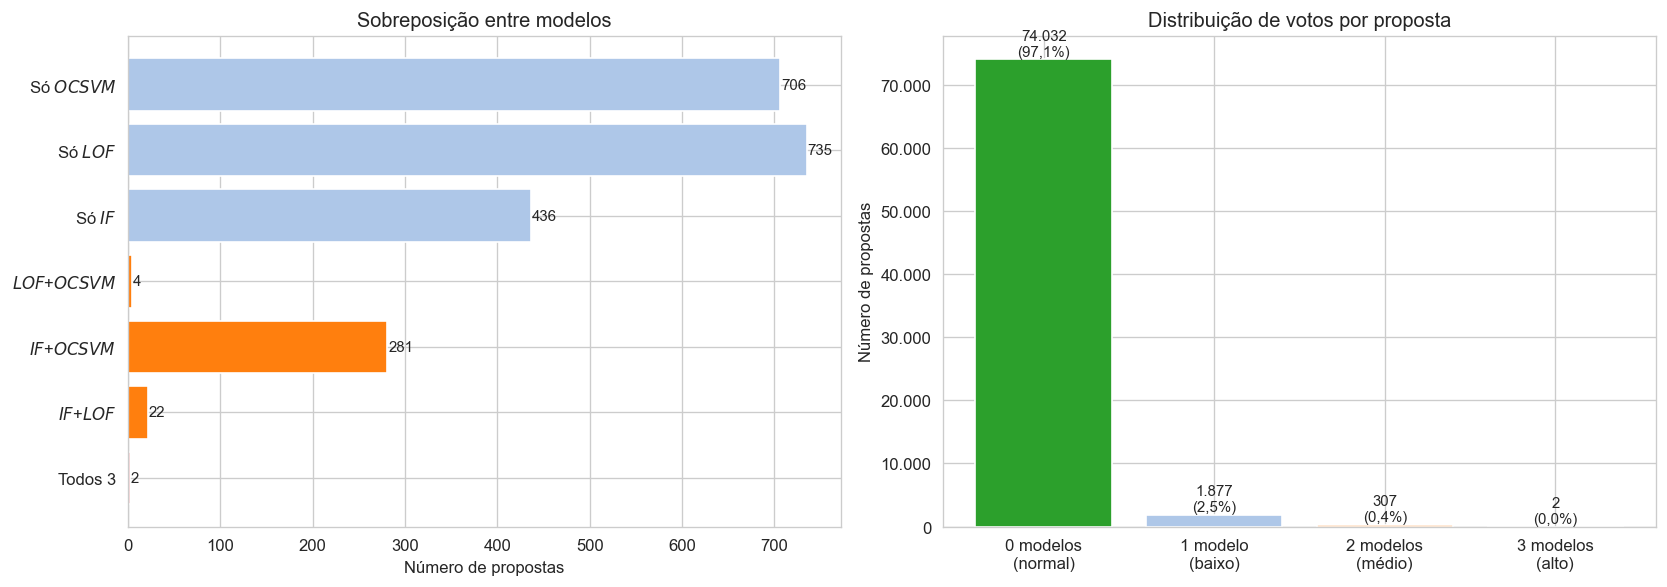

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

IF_, LOF_, OCSVM_ = r'$\mathit{IF}$', r'$\mathit{LOF}$', r'$\mathit{OCSVM}$'
labels_overlap = [
    'Todos 3', f'{IF_}+{LOF_}', f'{IF_}+{OCSVM_}', f'{LOF_}+{OCSVM_}',
    f'Só {IF_}', f'Só {LOF_}', f'Só {OCSVM_}'
]
counts_overlap = [
    len(todos_3), len(if_lof), len(if_ocsvm), len(lof_ocsvm),
    len(so_if), len(so_lof), len(so_ocsvm)
]
colors = ['#d62728', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#aec7e8', '#aec7e8', '#aec7e8']
axes[0].barh(labels_overlap, counts_overlap, color=colors)
axes[0].set_xlabel('Número de propostas')
axes[0].set_title('Sobreposição entre modelos')
for i, v in enumerate(counts_overlap):
    axes[0].text(v + 1, i, br(v, 0), va='center', fontsize=9)
fmt_eixo(axes[0], 'x', 0)

votos_colors = ['#2ca02c', '#aec7e8', '#ff7f0e', '#d62728']
votos_labels = ['0 modelos\n(normal)', '1 modelo\n(baixo)', '2 modelos\n(médio)', '3 modelos\n(alto)']
bars = axes[1].bar(votos_labels, votos_dist.values, color=votos_colors)
axes[1].set_title('Distribuição de votos por proposta')
axes[1].set_ylabel('Número de propostas')
for bar, val in zip(bars, votos_dist.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{br(val, 0)}\n({br(val/len(df_feat)*100, 1)}%)',
                 ha='center', va='bottom', fontsize=9)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('data/output/fig_sobreposicao_modelos.png', bbox_inches='tight')
plt.show()

---
### 5. Construção do Ranking Combinado

**Critérios:**
1. **Votos** (primário): quantos dos 3 modelos sinalizaram a proposta como anômala
2. **Score combinado normalizado** (desempate): média dos 3 scores após normalização MinMax

In [12]:
mms = MinMaxScaler()

df_feat['if_score_norm']    = mms.fit_transform(-df_feat[['if_score']])    
df_feat['lof_score_norm']   = mms.fit_transform(df_feat[['lof_score']])
df_feat['ocsvm_score_norm'] = mms.fit_transform(-df_feat[['ocsvm_score']]) 

df_feat['score_combinado'] = df_feat[[
    'if_score_norm', 'lof_score_norm', 'ocsvm_score_norm'
]].mean(axis=1)

print(f'Score combinado — min: {df_feat["score_combinado"].min():.4f}, '
      f'max: {df_feat["score_combinado"].max():.4f}, '
      f'mediana: {df_feat["score_combinado"].median():.4f}')

Score combinado — min: 0.0163, max: 0.8529, mediana: 0.1842


In [13]:
df_ranking = pd.concat([
    df_ids.reset_index(drop=True),
    df_feat[[
        'if_score', 'if_label', 'if_score_norm',
        'lof_score', 'lof_label', 'lof_score_norm',
        'ocsvm_score', 'ocsvm_label', 'ocsvm_score_norm',
        'votos', 'score_combinado'
    ]].reset_index(drop=True)
], axis=1)

df_ranking = df_ranking.sort_values(
    ['votos', 'score_combinado'],
    ascending=[False, False]
).reset_index(drop=True)

df_ranking['posicao_risco'] = df_ranking.index + 1  # 1 = mais anômalo

print(f'Ranking construído: {len(df_ranking)} propostas')
print(f'\nTop 10 — propostas com maior risco:')
df_ranking[['posicao_risco', 'cnpj_forn_norm', 'orgaoEntidadeCnpj',
            'votos', 'score_combinado']].head(10)

Ranking construído: 76218 propostas

Top 10 — propostas com maior risco:


,posicao_risco,cnpj_forn_norm,orgaoEntidadeCnpj,votos,score_combinado
0,1,8961997000158,9773169000159,3,0.852867
1,2,27664970300,29979036000140,3,0.454665
2,3,52105018000151,10571982000125,2,0.574701
3,4,51026267000199,24416174000106,2,0.546556
4,5,51026267000199,24416174000106,2,0.542440
5,6,51397666000166,5440725000114,2,0.490791
6,7,46974377000142,508903000188,2,0.489618
7,8,48902042000144,9822982000171,2,0.483499
8,9,37430723000130,9822982000171,2,0.472695
9,10,36851568000163,9822982000171,2,0.467060


In [14]:
df_ranking.to_csv('data/output/ranking_parcial.csv', index=False)
print(f'Ranking salvo em data/output/ranking_parcial.csv ({len(df_ranking)} linhas)')

Ranking salvo em data/output/ranking_parcial.csv (76218 linhas)


---
### 6. Análise do Perfil das Propostas de Alto Risco

In [15]:
alto_risco = df_ranking[df_ranking['votos'] >= 2].copy()
normal     = df_ranking[df_ranking['votos'] == 0].copy()

print(f'Propostas de alto risco (≥2 modelos): {len(alto_risco)} ({len(alto_risco)/len(df_ranking):.2%})')
print(f'  - Flagadas pelos 3 modelos: {(alto_risco["votos"] == 3).sum()}')
print(f'  - Flagadas por 2 modelos:   {(alto_risco["votos"] == 2).sum()}')
print(f'\nTotal normal (0 votos): {len(normal)} ({len(normal)/len(df_ranking):.2%})')

Propostas de alto risco (≥2 modelos): 309 (0.41%)
  - Flagadas pelos 3 modelos: 2
  - Flagadas por 2 modelos:   307

Total normal (0 votos): 74032 (97.13%)


In [16]:
df_perfil = df_full.copy()
df_perfil['votos']          = df_feat['votos'].values
df_perfil['score_combinado'] = df_feat['score_combinado'].values

# nome da modalidade (para os gráficos), reconstruído a partir das dummies usadas nos modelos
mod_cols = ['modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao']
df_perfil['modalidade'] = (df_perfil[mod_cols].idxmax(axis=1)
                           .str.replace('modalidade_', '', regex=False)
                           .replace({'Licitacao': 'Licitação'}))

alto = df_perfil[df_perfil['votos'] >= 2]
norm = df_perfil[df_perfil['votos'] == 0]

print(f'Alto risco (≥2 votos): {len(alto)} propostas ({len(alto)/len(df_perfil):.2%})')
print(f'Normal (0 votos): {len(norm)} propostas ({len(norm)/len(df_perfil):.2%})')

Alto risco (≥2 votos): 309 propostas (0.41%)
Normal (0 votos): 74032 propostas (97.13%)


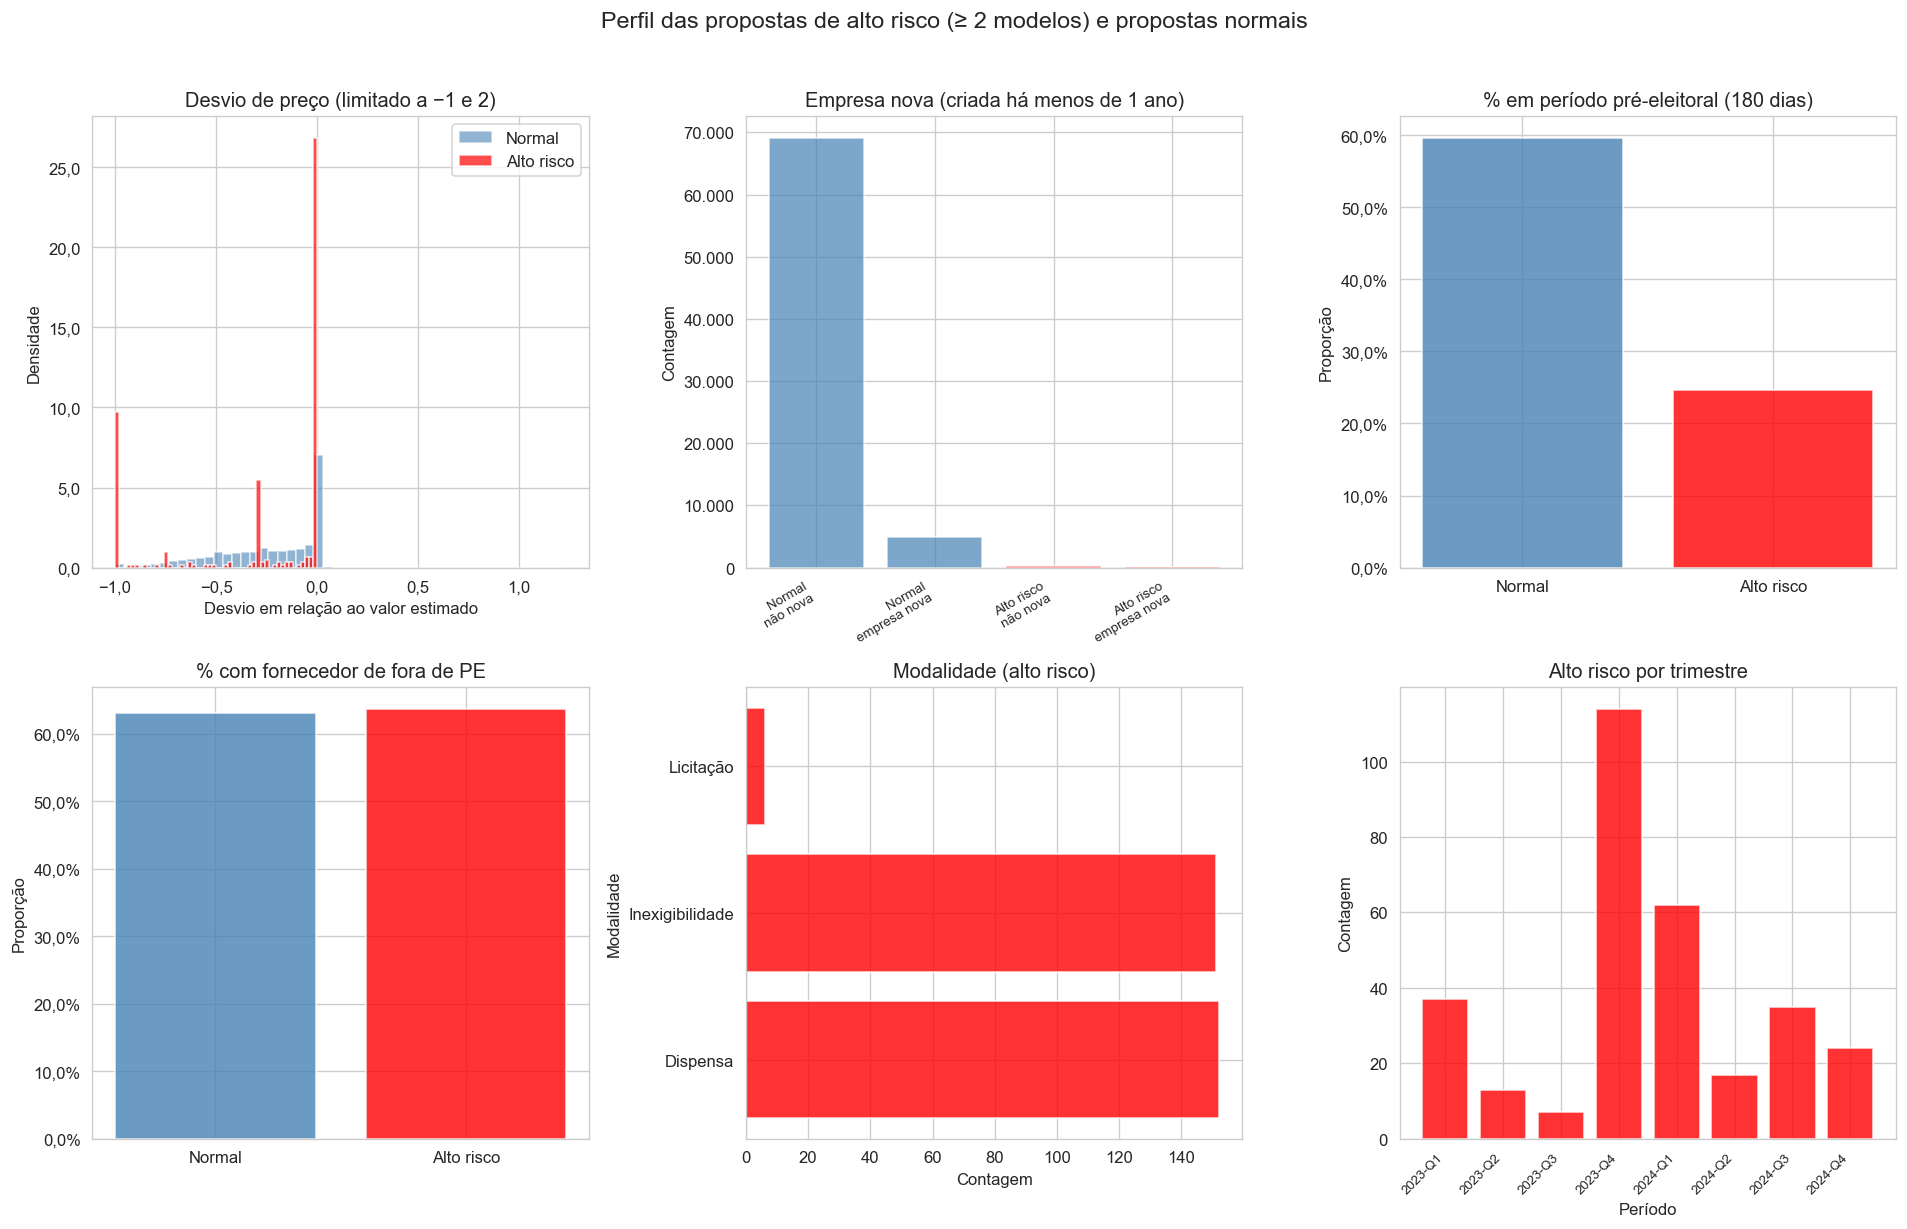

Figura salva em data/output/fig_perfil_alto_risco.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Desvio de preço
axes[0,0].hist(norm['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.6, label='Normal', color='steelblue', density=True)
axes[0,0].hist(alto['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.7, label='Alto risco', color='red', density=True)
axes[0,0].set_title('Desvio de preço (limitado a \u22121 e 2)')
axes[0,0].set_xlabel('Desvio em relação ao valor estimado')
axes[0,0].set_ylabel('Densidade')
axes[0,0].legend()
fmt_eixo(axes[0,0], 'x', 1)
fmt_eixo(axes[0,0], 'y', 1)

# 2. Empresa nova
for group, lbl, color in [(norm, 'Normal', 'steelblue'), (alto, 'Alto risco', 'red')]:
    axes[0,1].bar([lbl + '\nnão nova', lbl + '\nempresa nova'],
                  [(group['empresa_nova'] == 0).sum(), (group['empresa_nova'] == 1).sum()],
                  color=color, alpha=0.7)
axes[0,1].set_title('Empresa nova (criada há menos de 1 ano)')
axes[0,1].set_ylabel('Contagem')
fmt_eixo(axes[0,1], 'y', 0)
plt.setp(axes[0,1].get_xticklabels(), rotation=30, ha='right', fontsize=8)

# 3. Período pré-eleitoral
pre_norm = (norm['pre_eleitoral_180d'] == 1).mean()
pre_alto = (alto['pre_eleitoral_180d'] == 1).mean()
axes[0,2].bar(['Normal', 'Alto risco'], [pre_norm, pre_alto],
              color=['steelblue', 'red'], alpha=0.8)
axes[0,2].set_title('% em período pré-eleitoral (180 dias)')
axes[0,2].set_ylabel('Proporção')
fmt_eixo(axes[0,2], 'y', 1, pct=True)

# 4. Fornecedor fora de PE
fpe_norm = (norm['fornecedor_fora_pe'] == 1).mean()
fpe_alto = (alto['fornecedor_fora_pe'] == 1).mean()
axes[1,0].bar(['Normal', 'Alto risco'], [fpe_norm, fpe_alto],
              color=['steelblue', 'red'], alpha=0.8)
axes[1,0].set_title('% com fornecedor de fora de PE')
axes[1,0].set_ylabel('Proporção')
fmt_eixo(axes[1,0], 'y', 1, pct=True)

# 5. Modalidade
mod_alto = alto['modalidade'].value_counts()
axes[1,1].barh(mod_alto.index, mod_alto.values, color='red', alpha=0.8)
axes[1,1].set_title('Modalidade (alto risco)')
axes[1,1].set_xlabel('Contagem')
axes[1,1].set_ylabel('Modalidade')
fmt_eixo(axes[1,1], 'x', 0)

# 6. Distribuição temporal (votos ≥2 por trimestre)
alto_trim = alto.groupby(['ano', 'trimestre']).size().reset_index(name='n')
alto_trim['periodo'] = alto_trim['ano'].astype(str) + '-Q' + alto_trim['trimestre'].astype(str)
axes[1,2].bar(alto_trim['periodo'], alto_trim['n'], color='red', alpha=0.8)
axes[1,2].set_title('Alto risco por trimestre')
axes[1,2].set_xlabel('Período')
axes[1,2].set_ylabel('Contagem')
fmt_eixo(axes[1,2], 'y', 0)
plt.setp(axes[1,2].get_xticklabels(), rotation=45, ha='right', fontsize=8)

plt.suptitle('Perfil das propostas de alto risco (≥ 2 modelos) e propostas normais', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('data/output/fig_perfil_alto_risco.png', bbox_inches='tight')
plt.savefig('figuras_tcc/image4.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em data/output/fig_perfil_alto_risco.png')

---
### 7. Top-20 da Tabela de Risco

In [18]:
top20_ids = df_ranking.head(20)[['posicao_risco', 'orgaoEntidadeCnpj', 'cnpj_forn_norm',
                                  'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
                                  'votos', 'score_combinado']].copy()

top20_completo = top20_ids.merge(
    df_perfil[['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
               'cnpj_forn_norm', 'desvio_item_estimado', 'modalidade',
               'empresa_nova', 'fornecedor_fora_pe', 'pre_eleitoral_180d',
               'dias_para_eleicao', 'idade_empresa_anos']],
    on=['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
        'numeroItem', 'cnpj_forn_norm'],
    how='left'
)

print('=== Top 20 Propostas de Maior Risco ===')
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 200)
top20_completo

=== Top 20 Propostas de Maior Risco ===


,posicao_risco,orgaoEntidadeCnpj,cnpj_forn_norm,anoCompraPncp,sequencialCompraPncp,numeroItem,votos,score_combinado,desvio_item_estimado,modalidade,empresa_nova,fornecedor_fora_pe,pre_eleitoral_180d,dias_para_eleicao,idade_empresa_anos
0,1,9773169000159,8961997000158,2023,8,1,3,0.852867,0.000000,Dispensa,0,0,0,340,38.891170
1,2,29979036000140,27664970300,2024,271,1,3,0.454665,-0.899752,Inexigibilidade,0,1,1,68,28.804928
2,3,10571982000125,52105018000151,2023,321,1,2,0.574701,-0.439577,Dispensa,1,1,0,306,0.246407
3,4,24416174000106,51026267000199,2024,20,3,2,0.546556,-0.452723,Dispensa,1,1,0,240,0.659822
4,5,24416174000106,51026267000199,2024,20,2,2,0.542440,-0.196787,Dispensa,1,1,0,240,0.659822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,20,508903000188,0,2024,2891,1,2,0.465242,0.000000,Dispensa,0,1,1,33,28.804928
226,20,508903000188,0,2024,2891,1,2,0.465242,0.000000,Dispensa,0,1,1,33,28.804928
227,20,508903000188,0,2024,2891,1,2,0.465242,0.000000,Dispensa,0,1,1,33,28.804928
228,20,508903000188,0,2024,2891,1,2,0.465242,0.000000,Dispensa,0,1,1,33,28.804928
